# Focal Loss : apprendre sur des classes déséquilibrées

[![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/moncoachdata/cercle-des-experts/blob/main/ml-classique-et-deep-learning/techniques-ml-avancees-focal-loss-breathing-kmeans-features-cycliques/techniques-ml-avancees-focal-loss-breathing-kmeans-features-cycliques.ipynb)

📖 **Le mini-cours complet** : [Booste tes modèles ML sans changer d'algorithme (Partie 2)](https://www.monshotdata.com/p/techniques-ml-avancees-focal-loss-breathing-kmeans-features-cycliques)

🧭 **Le cours** : [ML classique et Deep Learning › 2.2 Régression et classification](https://www.monshotdata.com/mini-cours/ml-classique-et-deep-learning#h2sc22)

---

Sur un jeu de données déséquilibré à 90 / 10, un réseau de neurones entraîné avec la Binary Cross-Entropy finit souvent par **prédire toujours la classe majoritaire** et affiche pourtant 90 % de précision. La *focal loss* change la façon dont chaque exemple compte dans la loss, sans toucher à l'architecture ni à l'algorithme. Tu vas le voir côte à côte, avec les régions de décision.

**À la fin de ce notebook, tu sauras :**

- pourquoi la BCE se laisse « écraser » par les exemples faciles de la classe majoritaire ;
- comment la focal loss réduit le poids des exemples déjà bien classés (le facteur de *downweighting* contrôlé par γ) ;
- comment l'implémenter en PyTorch en quelques lignes et la comparer à la BCE sur un jeu de données déséquilibré.


### Avant de lancer

Aucun fichier externe, aucun GPU nécessaire : **Exécution → Tout exécuter** (environ une minute). Les graines aléatoires sont fixées, tu dois donc retrouver exactement les mêmes chiffres que ci-dessous. Ce notebook illustre la technique n°10 du mini-cours (Focal Loss).

🧪 *Testé le 20 novembre 2026 avec Python 3.13, PyTorch 2.x, scikit-learn et Matplotlib dans leurs versions de Colab.*

## 1. Mise en place

In [1]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader, TensorDataset
from sklearn.datasets import make_classification

sns.set()

In [2]:
import logging
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)  # évite les avertissements si la police n'est pas installée

colors = ['#fe7c73', '#2471A3']
plt.rcParams['font.family'] = ['Comic Sans MS', 'sans-serif']
torch.manual_seed(20)

## 2. Un jeu de données déséquilibré

On génère 1000 points en 2D avec un ratio de **10 % pour la classe 0** (minoritaire) et **90 % pour la classe 1** (majoritaire). Un modèle qui prédit toujours la classe 1 obtiendrait déjà ≈ 90 % de précision : c'est précisément le piège.

In [3]:
# Définition du ratio
ratio = {0: 10, 1: 90}

# Génération du dataset déséquilibré
X, y = make_classification(
    n_samples=1000,   # Nombre total d'exemples
    n_features=2,    # Nombre de features
    n_informative=2,
    n_redundant=0,
    weights=[ratio[0] / 100, ratio[1] / 100],  # Distribution des classes
    class_sep=0.5,
    random_state=6
)

# Affichage de la distribution des classes
unique, counts = np.unique(y, return_counts=True)
class_distribution = dict(zip(unique, counts))
print("Distribution des classes :", class_distribution)

Distribution des classes : {np.int64(0): np.int64(103), np.int64(1): np.int64(897)}


On visualise les deux classes : la classe minoritaire (en bleu) est noyée au milieu de la classe majoritaire.

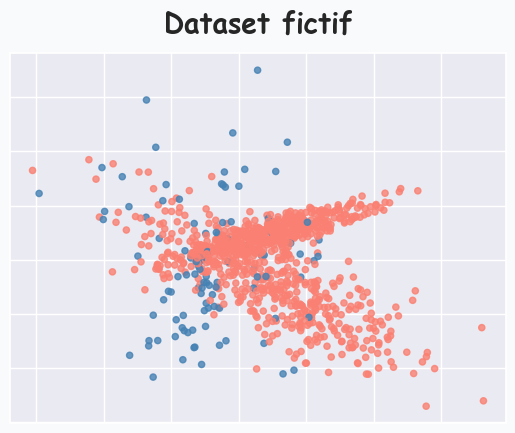

In [4]:
fig, ax = plt.subplots(facecolor="#f8fafc")

colors = {0: 'steelblue', 1: 'salmon'}

plt.scatter(X[:, 0], X[:, 1],
            c=[colors[int(i)] for i in y],
            s=20, alpha=0.8)

ax.set_title("Dataset fictif", fontsize=20, fontweight="bold", pad=15)
ax.set_xticklabels([])
ax.set_yticklabels([])

plt.show()

## 3. Le réseau de neurones

Un petit réseau dense avec une couche cachée de 256 neurones. On utilisera **exactement la même architecture** pour les deux entraînements : seule la fonction de loss changera.

In [5]:
class SimpleNN(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super(SimpleNN, self).__init__()
        
        self.relu = nn.ReLU()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.fc2 = nn.Linear(hidden_size, output_size)
        self.fc3 = nn.Linear(output_size, output_size)

    def forward(self, x):
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        x = self.relu(x)
        x = self.fc3(x)
        return x

Une fonction utilitaire pour mesurer la précision (accuracy) sur un `DataLoader`.

In [6]:
def compute_accuracy(model, dataloader):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in dataloader:
            outputs = model(inputs)
            predictions = (torch.sigmoid(outputs) > 0.5).float()
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    accuracy = correct / total
    return accuracy

On convertit les données en tenseurs PyTorch et on prépare le `DataLoader`.

In [7]:
# Conversion des données en tenseurs PyTorch
X_tensor = torch.FloatTensor(X)
y_tensor = torch.FloatTensor(y).view(-1, 1)  # S'assurer que y est un vecteur colonne pour la BCE loss

# Création d'un DataLoader pour le batching
dataset = TensorDataset(X_tensor, y_tensor)
dataloader = DataLoader(dataset, batch_size=32, shuffle=True)

## 4. Premier entraînement : la BCE

La Binary Cross-Entropy traite de la même façon une erreur sur la classe minoritaire et une erreur sur la classe majoritaire. Avec 90 % d'exemples « faciles », ce sont eux qui dominent la loss.

In [8]:
# Définition du modèle, de la fonction de loss et de l'optimiseur
input_size = 2
hidden_size = 256
output_size = 1

model = SimpleNN(input_size, hidden_size, output_size)
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

On entraîne pendant 100 époques. Remarque la précision : elle plafonne à **0,897**, soit exactement la proportion de la classe majoritaire. Le réseau prédit tout le temps la classe 1.

In [9]:
# Boucle d'entraînement
epochs = 100
for epoch in range(epochs):
    for inputs, labels in dataloader:
        optimizer.zero_grad()       # Remise à zéro des gradients
        outputs = model(inputs)     # Forward pass
        loss = criterion(outputs, labels)  # Calcul de la BCE loss
        loss.backward()             # Backward pass
        optimizer.step()            # Mise à jour des poids

    accuracy = compute_accuracy(model, dataloader)

    if epoch % 10 == 0:
        print(f'Epoch {epoch + 1}/{epochs}, Loss: {round(loss.item(), 2)}, Accuracy: {accuracy}')

Epoch 1/100, Loss: 0.84, Accuracy: 0.103
Epoch 11/100, Loss: 0.68, Accuracy: 0.897
Epoch 21/100, Loss: 0.63, Accuracy: 0.897
Epoch 31/100, Loss: 0.59, Accuracy: 0.897
Epoch 41/100, Loss: 0.38, Accuracy: 0.897
Epoch 51/100, Loss: 0.56, Accuracy: 0.897
Epoch 61/100, Loss: 0.42, Accuracy: 0.897
Epoch 71/100, Loss: 0.23, Accuracy: 0.897
Epoch 81/100, Loss: 0.21, Accuracy: 0.897
Epoch 91/100, Loss: 0.38, Accuracy: 0.897


### Les régions de décision de la BCE

On évalue le modèle sur une grille de points couvrant tout le plan, puis on colorie chaque zone selon la classe prédite.

In [10]:
# Création d'une grille pour la visualisation
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.01),
                     np.arange(y_min, y_max, 0.01))

# Mise à plat de la grille et prédictions par mini-batchs
meshgrid_data = np.c_[xx.ravel(), yy.ravel()]

# Définition de la taille des batchs
batch_size = 32

# Découpage de meshgrid_data en mini-batchs
num_batches = len(meshgrid_data) // batch_size
remainder = len(meshgrid_data) % batch_size

In [11]:
# Prédictions par mini-batchs
predictions = []
model.eval()
with torch.no_grad():
    for i in range(num_batches):
        start_idx = i * batch_size
        end_idx = (i + 1) * batch_size
        batch_tensor = torch.FloatTensor(meshgrid_data[start_idx:end_idx])
        batch_predictions = torch.sigmoid(model(batch_tensor)).numpy()
        predictions.extend(batch_predictions)

    # Traitement du reste
    if remainder > 0:
        batch_tensor = torch.FloatTensor(meshgrid_data[-remainder:])
        batch_predictions = torch.sigmoid(model(batch_tensor)).numpy()
        predictions.extend(batch_predictions)

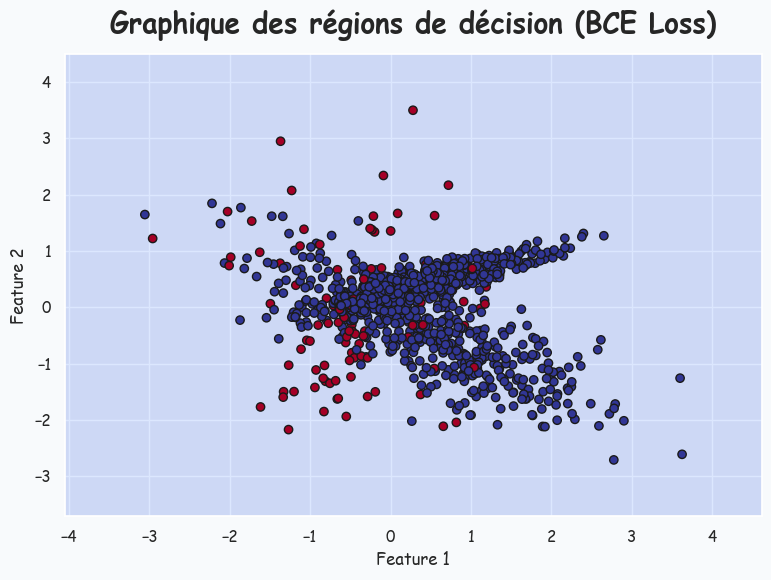

In [12]:
# Reformatage des prédictions pour correspondre à la forme de la grille
predictions = np.array(predictions).reshape(xx.shape)
predictions = np.where(predictions >= 0.5, 1, 0)

# Tracé de la frontière de décision
plt.figure(figsize=(9, 6), facecolor="#f8fafc")
plt.contourf(xx, yy, predictions, cmap='coolwarm', alpha=0.3)
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.RdYlBu,
            edgecolors='k', marker='o')
plt.title('Graphique des régions de décision (BCE Loss)',
          fontsize=20, fontweight="bold", pad=15)
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.show()

## 5. Deuxième entraînement : la focal loss

La focal loss multiplie la BCE par un facteur $(1 - p_t)^\gamma$ : plus le modèle est sûr de lui sur un exemple, plus cet exemple compte peu. Le paramètre `gamma` règle l'intensité de ce « downweighting » et `alpha` pondère la loss (le mini-cours détaille son rôle).

In [13]:
class FocalLoss(nn.Module):
    def __init__(self, gamma=5, alpha=0.1):
        super(FocalLoss, self).__init__()
        self.gamma = gamma
        self.alpha = alpha

    def forward(self, inputs, targets):
        BCE_loss = nn.functional.binary_cross_entropy_with_logits(inputs, targets, reduction='none')
        pt = torch.exp(-BCE_loss)
        focal_loss = self.alpha * (1 - pt) ** self.gamma * BCE_loss
        return torch.mean(focal_loss)

On reprend le même réseau, avec la focal loss à la place de la BCE.

In [14]:
# Définition du modèle, de la fonction de loss et de l'optimiseur
input_size = 2
hidden_size = 256
output_size = 1

model = SimpleNN(input_size, hidden_size, output_size)
criterion = FocalLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

On relance la même boucle d'entraînement. La précision grimpe au-dessus de 0,9 et continue à progresser : le modèle apprend enfin quelque chose de la classe minoritaire. La loss affichée est très petite car la focal loss atténue fortement les exemples faciles.

In [15]:
# Boucle d'entraînement
epochs = 100
for epoch in range(epochs):
    for inputs, labels in dataloader:
        optimizer.zero_grad()            # Remise à zéro des gradients
        outputs = model(inputs)          # Forward pass
        loss = criterion(outputs, labels)  # Calcul de la Focal loss
        loss.backward()                  # Backward pass
        optimizer.step()                 # Mise à jour des poids

    accuracy = compute_accuracy(model, dataloader)

    if epoch % 10 == 0:
        print(f'Epoch {epoch + 1}/{epochs}, Loss: {round(loss.item(), 2)}, Accuracy: {accuracy}')

Epoch 1/100, Loss: 0.0, Accuracy: 0.897
Epoch 11/100, Loss: 0.0, Accuracy: 0.92
Epoch 21/100, Loss: 0.0, Accuracy: 0.928
Epoch 31/100, Loss: 0.0, Accuracy: 0.93
Epoch 41/100, Loss: 0.0, Accuracy: 0.928
Epoch 51/100, Loss: 0.0, Accuracy: 0.927
Epoch 61/100, Loss: 0.0, Accuracy: 0.931
Epoch 71/100, Loss: 0.0, Accuracy: 0.931
Epoch 81/100, Loss: 0.0, Accuracy: 0.932
Epoch 91/100, Loss: 0.0, Accuracy: 0.935


### Les régions de décision avec la focal loss

À comparer avec le graphique de la BCE : la zone de la classe minoritaire n'est plus effacée.

In [16]:
# Création d'une grille pour la visualisation
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.01),
                     np.arange(y_min, y_max, 0.01))

# Mise à plat de la grille et prédictions par mini-batchs
meshgrid_data = np.c_[xx.ravel(), yy.ravel()]

# Définition de la taille des batchs
batch_size = 32

# Découpage de meshgrid_data en mini-batchs
num_batches = len(meshgrid_data) // batch_size
remainder = len(meshgrid_data) % batch_size

In [17]:
# Prédictions par mini-batchs
predictions = []
model.eval()
with torch.no_grad():
    for i in range(num_batches):
        start_idx = i * batch_size
        end_idx = (i + 1) * batch_size
        batch_tensor = torch.FloatTensor(meshgrid_data[start_idx:end_idx])
        batch_predictions = torch.sigmoid(model(batch_tensor)).numpy()
        predictions.extend(batch_predictions)

    # Traitement du reste
    if remainder > 0:
        batch_tensor = torch.FloatTensor(meshgrid_data[-remainder:])
        batch_predictions = torch.sigmoid(model(batch_tensor)).numpy()
        predictions.extend(batch_predictions)

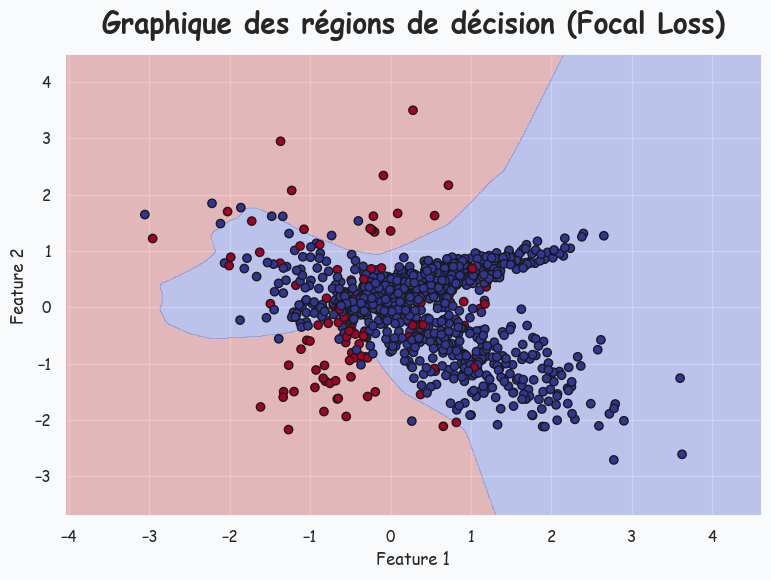

In [18]:
# Reformatage des prédictions pour correspondre à la forme de la grille
predictions = np.array(predictions).reshape(xx.shape)
predictions = np.where(predictions >= 0.5, 1, 0)

# Tracé de la frontière de décision
plt.figure(figsize=(9, 6), facecolor="#f8fafc")
plt.contourf(xx, yy, predictions, cmap='coolwarm_r', alpha=0.3)
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.RdYlBu,
            edgecolors='k', marker='o')
plt.title('Graphique des régions de décision (Focal Loss)',
          fontsize=20, fontweight="bold", pad=15)
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.show()

---

## Pour aller plus loin

- [Booste tes modèles ML sans changer d'algorithme (Partie 1)](https://www.monshotdata.com/p/techniques-ml-avancees-regression-huber-knn-label-smoothing) — Huber, label smoothing et d'autres techniques
- [CORAL : comment forcer tes réseaux de neurones à respecter l'ordre naturel des classes](https://www.monshotdata.com/p/coral-classification-ordinale-pytorch) — la technique suivante de la série
- [Calibration des modèles ML (Partie 1)](https://www.monshotdata.com/p/calibration-modeles-machine-learning) — des probabilités fiables, au-delà de la précision